In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("../Data/reviews.csv")

In [5]:
df.shape

(10000, 5)

In [6]:
df.head()

,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store


In [7]:
df.info

<bound method DataFrame.info of       review_id                                        review_text sentiment  \
0             1  This product exceeded my expectations in sever...  Positive   
1             2  The item is uncomfortable to use and poorly de...  Negative   
2             3  The product comes with a charging adapter and ...   Neutral   
3             4  Customer support was slow and did not solve my...  Negative   
4             5  The design is simple, attractive, and comforta...  Positive   
...         ...                                                ...       ...   
9995       9996  The battery drains quickly and does not last a...  Negative   
9996       9997  I have been using the product for about one we...   Neutral   
9997       9998  The box included the accessories listed in the...   Neutral   
9998       9999  I really like this product; it is useful, reli...  Positive   
9999      10000  The battery lasts a long time and charges quic...  Positive   

       

In [8]:
df.isnull().sum()

review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["sentiment"].value_counts()

sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64

In [11]:
duplicate_count = df.duplicated().sum()
duplicate_count

np.int64(0)

In [12]:
required_columns = [
    "review_id",
    "review_text",
    "sentiment",
    "category",
    "source"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All expected columns are present.")

All expected columns are present.


In [13]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64

Total missing values: 0


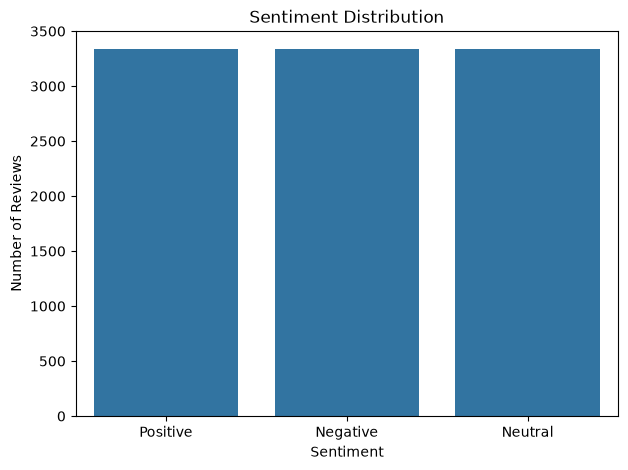

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [17]:
sentiment_percentage = (
    df["sentiment"]
    .value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

sentiment
Positive    33.34
Negative    33.33
Neutral     33.33
Name: proportion, dtype: float64


In [18]:
df["review_length"] = df["review_text"].str.len()
df[["review_text", "review_length"]].head()

,review_text,review_length
0,This product exceeded my expectations in sever...,92
1,The item is uncomfortable to use and poorly de...,79
2,The product comes with a charging adapter and ...,60
3,Customer support was slow and did not solve my...,102
4,"The design is simple, attractive, and comforta...",95


In [19]:
df["word_count"] = df["review_text"].apply(
    lambda text: len(str(text).split())
)

df[["review_text", "word_count"]].head()

,review_text,word_count
0,This product exceeded my expectations in sever...,16
1,The item is uncomfortable to use and poorly de...,15
2,The product comes with a charging adapter and ...,11
3,Customer support was slow and did not solve my...,19
4,"The design is simple, attractive, and comforta...",17


In [20]:
df["word_count"].describe()

count    10000.000000
mean        16.298200
std          3.929201
min          7.000000
25%         15.000000
50%         17.000000
75%         19.000000
max         25.000000
Name: word_count, dtype: float64

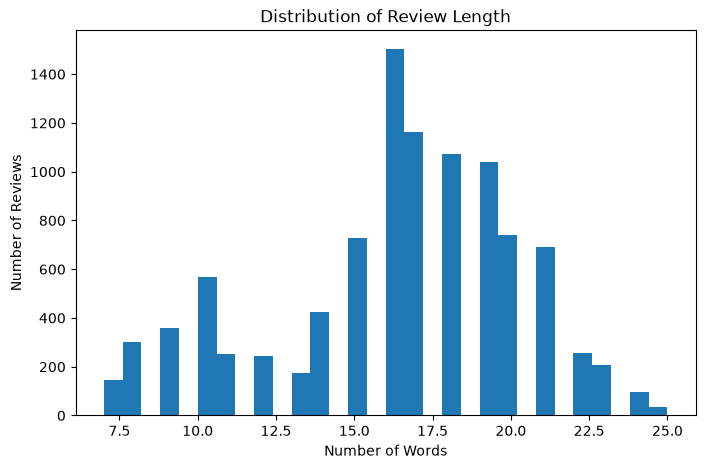

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(df["word_count"], bins=30)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

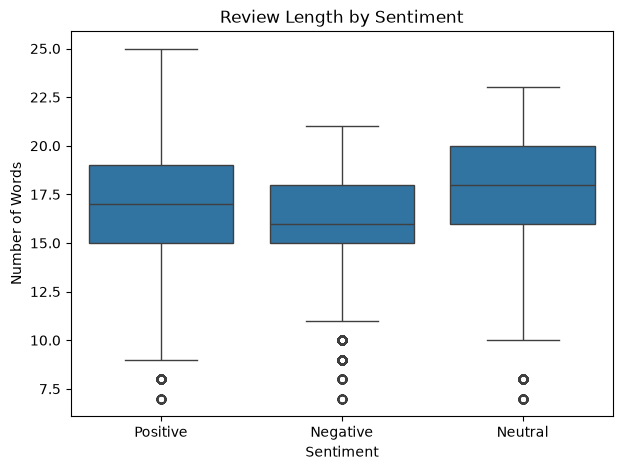

In [24]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="sentiment", y="word_count")

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.show()

In [25]:
df["category"].value_counts()

category
Travel            1305
Clothing          1288
Sports            1278
Beauty            1272
Home & Kitchen    1245
Electronics       1239
Food & Grocery    1205
Books             1168
Name: count, dtype: int64

In [26]:
print(df["source"].value_counts())

source
Online Store       2590
Customer Survey    2495
Website            2478
Mobile App         2437
Name: count, dtype: int64


In [27]:
df["clean_text"] = df["review_text"].str.lower()

df[["review_text", "clean_text"]].head()

,review_text,clean_text
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...
4,"The design is simple, attractive, and comforta...","the design is simple, attractive, and comforta..."


In [28]:
import re

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return text

df["clean_text"] = df["review_text"].apply(clean_text)

df[["review_text", "clean_text"]].head()

,review_text,clean_text
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...
4,"The design is simple, attractive, and comforta...",the design is simple attractive and comfortabl...


In [29]:
X = df["clean_text"]
y = df["sentiment"]

In [30]:
from sklearn.model_selection import  train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 8000
Testing data: 2000


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (8000, 266)
Testing shape: (2000, 266)


In [34]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [35]:
y_pred = model.predict(X_test_tfidf)

In [38]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_test, y_pred)
accuracy

1.0

In [39]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n    Negative       1.00      1.00      1.00       667\n     Neutral       1.00      1.00      1.00       666\n    Positive       1.00      1.00      1.00       667\n\n    accuracy                           1.00      2000\n   macro avg       1.00      1.00      1.00      2000\nweighted avg       1.00      1.00      1.00      2000\n'

In [40]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[667,   0,   0],
       [  0, 666,   0],
       [  0,   0, 667]])

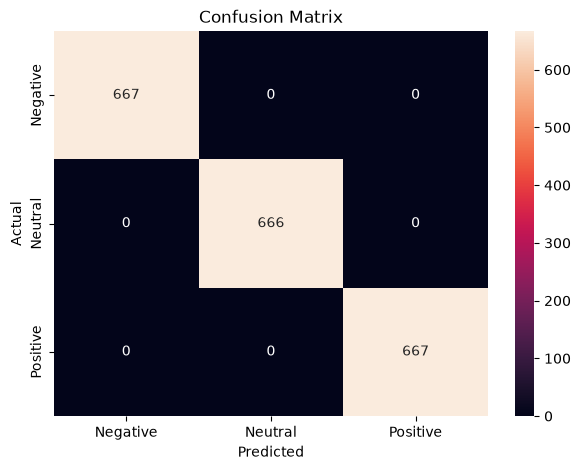

In [41]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [42]:
from sklearn.naive_bayes import MultinomialNB

In [43]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_accuracy

1.0

In [44]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X_train_tfidf,
    y_train,
    cv=5
)

print("Cross Validation Scores:", scores)
print("Average Score:", scores.mean())

Cross Validation Scores: [1. 1. 1. 1. 1.]
Average Score: 1.0


In [45]:
from sklearn.model_selection import GridSearchCV

parameters = {
    "C": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    parameters,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train_tfidf, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)

Best Parameters: {'C': 0.1}
Best Score: 1.0


In [47]:
final_model = grid_search.best_estimator_

final_pred = final_model.predict(X_test_tfidf)

final_accuracy = accuracy_score(y_test, final_pred)

print("Final Model Accuracy:", final_accuracy)

Final Model Accuracy: 1.0


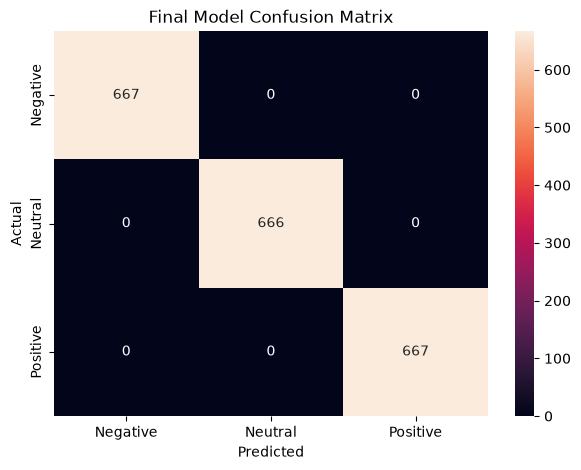

In [48]:
final_cm = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_
)

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [49]:
import pickle

In [50]:
with open("../models/sentiment_model.pkl", "wb") as file:
    pickle.dump(final_model, file)

with open("../models/tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

print("Model and vectorizer saved successfully")

Model and vectorizer saved successfully


In [51]:
test_reviews = [
    "I absolutely loved this product, it was amazing",
    "This product is terrible and I hate it",
    "The product is okay, nothing special"
]

test_clean = [clean_text(review) for review in test_reviews]

test_features = tfidf.transform(test_clean)

predictions = final_model.predict(test_features)

for review, prediction in zip(test_reviews, predictions):
    print("Review:", review)
    print("Prediction:", prediction)
    print()

Review: I absolutely loved this product, it was amazing
Prediction: Positive

Review: This product is terrible and I hate it
Prediction: Positive

Review: The product is okay, nothing special
Prediction: Neutral



In [53]:
for sentiment in ["Positive", "Negative", "Neutral"]:
    print("\n", sentiment)
    print(df[df["sentiment"] == sentiment]["review_text"].head(5).to_string(index=False))


 Positive
This product exceeded my expectations in severa...
The design is simple, attractive, and comfortab...
This is one of the better purchases I have made...
The product works perfectly and feels well made...
Customer support responded quickly and solved m...

 Negative
The item is uncomfortable to use and poorly des...
Customer support was slow and did not solve my ...
The delivery was late and the package arrived d...
The order was incorrect and fixing it took too ...
The packaging was poor and some parts were miss...

 Neutral
The product comes with a charging adapter and a...
I have been using the product for about one wee...
The store offers standard and express delivery ...
The item has a one-year warranty according to t...
The box included the accessories listed in the ...


In [54]:
test_reviews = [
    "This product is terrible and I hate it",
    "This product is amazing and I love it",
    "The product is okay and works as expected"
]

test_clean = [clean_text(x) for x in test_reviews]

test_features = tfidf.transform(test_clean)

print("Predictions:")
print(final_model.predict(test_features))

print("\nProbabilities:")
print(final_model.predict_proba(test_features))

Predictions:
['Positive' 'Positive' 'Positive']

Probabilities:
[[0.121726   0.16093292 0.71734108]
 [0.121726   0.16093292 0.71734108]
 [0.17548704 0.18897614 0.63553682]]
